## **Exercices**

### Exercice 1

Prédiction de la consommation électrique avec un Transformer

Objectif : utiliser les 24 dernières heures de consommation électrique pour prédire la consommation de l’heure suivante.

Dataset : Individual Household Electric Power Consumption, disponible sur UCI Machine Learning Repository. Utiliser la variable Global_active_power, puis agréger les mesures par heure pour obtenir une série de puissance moyenne en kW.

1. Préparation des données

À partir du fichier household_power_consumption.txt :

In [1]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False,
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
)

puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

# Puissance moyenne horaire : conserver les heures suffisamment renseignées.
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

# Découpage chronologique : 70 % entraînement, 15 % validation, 15 % test.
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

# Normalisation calculée uniquement sur l'entraînement.
moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

# Une entrée contient 24 heures consécutives.
# Écarter les fenêtres comportant des valeurs manquantes.
fenetre = 24
X, y, dates_cibles = [], [], []

for i in range(fenetre, n):
    sequence = valeurs[i - fenetre:i]
    cible = valeurs[i]

    if np.isfinite(sequence).all() and np.isfinite(cible):
        X.append(sequence)
        y.append(cible)
        dates_cibles.append(i)

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
dates_cibles = np.array(dates_cibles)

train_mask = dates_cibles < fin_train
val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
test_mask = dates_cibles >= fin_val

train_loader = DataLoader(
    TensorDataset(X[train_mask], y[train_mask]),
    batch_size=64,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(X[val_mask], y[val_mask]),
    batch_size=64,
)
test_loader = DataLoader(
    TensorDataset(X[test_mask], y[test_mask]),
    batch_size=64,
)

2. Implémentation demandée

Construire un modèle EnergyTransformer comprenant :
- une projection Linear(1, 32) ;
- un encodage positionnel des 24 heures ;
- deux couches TransformerEncoderLayer, avec d_model=32, nhead=4, dim_feedforward=128, dropout=0.1 et batch_first=True ;
- une couche Linear(32, 1) appliquée à la représentation de la dernière heure.
Entrée                     : (batch, 24, 1)
Après projection           : (batch, 24, 32)
Après Transformer Encoder  : (batch, 24, 32)
Prédiction                 : (batch, 1)
3. Entraînement et évaluation
1. Entraîner avec Adam, un taux d’apprentissage de 0.001 et une perte MSE, pendant au maximum 20 époques.
2. Conserver le modèle ayant la meilleure perte de validation.
3. Revenir à l’échelle originale avec valeur * ecart_type + moyenne.
4. Calculer la MAE et la RMSE en kW sur le test.
5. Comparer avec deux références :
   - Persistance : prédire la valeur de la dernière heure observée.
   - Référence journalière : prédire la valeur observée 24 heures auparavant.
6. Tracer les prédictions et les observations sur sept jours consécutifs du test.
L’évaluation se fait heure par heure : chaque prédiction utilise les 24 mesures réellement observées avant son heure cible.

4. Questions de réflexion
- Le Transformer améliore-t-il les deux références ?
- Une fenêtre de 168 heures permet-elle de mieux capturer les habitudes hebdomadaires ?
- Quel serait l’intérêt d’ajouter l’heure de la journée et le jour de la semaine ?
- Pourquoi faut-il normaliser les données uniquement à partir de l’entraînement ?
- La cible étant une puissance moyenne en kW, comment adapter la préparation pour prédire une énergie consommée en kWh ?

In [2]:
# 2. EnergyTransformer 
import torch.nn as nn

class EnergyTransformer(nn.Module):
    def __init__(self, longueur=24, dimension=32):
        super().__init__()
        self.projection = nn.Linear(1, dimension)
        self.positions = nn.Embedding(longueur, dimension)
        couche = nn.TransformerEncoderLayer(
            d_model=dimension, nhead=4, dim_feedforward=128,
            dropout=0.1, batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2)
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):                        # (B, 24, 1)
        x = self.projection(x)                   # (B, 24, 32)
        indices = torch.arange(x.size(1), device=x.device)
        x = x + self.positions(indices).unsqueeze(0)
        x = self.encodeur(x)                     # (B, 24, 32)
        return self.sortie(x[:, -1, :])          # (B, 1)

torch.manual_seed(42)
appareil = "cuda" if torch.cuda.is_available() else "cpu"
modele = EnergyTransformer().to(appareil)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.001)

In [3]:
# 3 / 4 / 5
import copy

def perte_moyenne(loader):
    modele.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(appareil), yb.to(appareil)
            total += critere(modele(xb), yb).item() * len(xb)
            n += len(xb)
    return total / n

meilleure_val, meilleur_etat = float("inf"), None

for epoch in range(20):
    modele.train()
    total, n = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(appareil), yb.to(appareil)
        perte = critere(modele(xb), yb)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        total += perte.item() * len(xb)
        n += len(xb)

    perte_val = perte_moyenne(val_loader)
    if perte_val < meilleure_val:
        meilleure_val = perte_val
        meilleur_etat = copy.deepcopy(modele.state_dict())

    print(f"Epoch {epoch+1:2d} | train {total/n:.4f} | val {perte_val:.4f}")

modele.load_state_dict(meilleur_etat)

Epoch  1 | train 0.4697 | val 0.4080
Epoch  2 | train 0.4323 | val 0.3935
Epoch  3 | train 0.4258 | val 0.3968
Epoch  4 | train 0.4183 | val 0.3866
Epoch  5 | train 0.4149 | val 0.3822
Epoch  6 | train 0.4122 | val 0.3910
Epoch  7 | train 0.4115 | val 0.3840
Epoch  8 | train 0.4075 | val 0.3918
Epoch  9 | train 0.4075 | val 0.3840
Epoch 10 | train 0.4051 | val 0.3871
Epoch 11 | train 0.4025 | val 0.3889
Epoch 12 | train 0.3998 | val 0.3991
Epoch 13 | train 0.4003 | val 0.3819
Epoch 14 | train 0.3993 | val 0.3925
Epoch 15 | train 0.3965 | val 0.3825
Epoch 16 | train 0.3967 | val 0.3921
Epoch 17 | train 0.3950 | val 0.3802
Epoch 18 | train 0.3956 | val 0.3782
Epoch 19 | train 0.3967 | val 0.3807
Epoch 20 | train 0.3934 | val 0.3840


<All keys matched successfully>

In [4]:
# 6 / 7 / 8
modele.eval()
with torch.no_grad():
    pred_norm = torch.cat([modele(xb.to(appareil)).cpu() for xb, _ in test_loader])

X_test, y_test = X[test_mask], y[test_mask]

def vers_kw(v):                                   # valeur * ecart_type + moyenne
    return v.numpy().reshape(-1) * ecart_type + moyenne

reel        = vers_kw(y_test)
pred        = vers_kw(pred_norm)
persistance = vers_kw(X_test[:, -1, :])   # dernière heure observée
journaliere = vers_kw(X_test[:, 0, :])    # même heure la veille (t-24)

def mae(a, b):  return np.mean(np.abs(a - b))
def rmse(a, b): return np.sqrt(np.mean((a - b) ** 2))

resultats = pd.DataFrame({                         
    "MAE (kW)":  [mae(reel, pred), mae(reel, persistance), mae(reel, journaliere)],
    "RMSE (kW)": [rmse(reel, pred), rmse(reel, persistance), rmse(reel, journaliere)],
}, index=["Transformer", "Persistance", "Référence journalière"])
print(resultats.round(4))

                       MAE (kW)  RMSE (kW)
Transformer              0.3412     0.4904
Persistance              0.3892     0.5884
Référence journalière    0.5133     0.7639


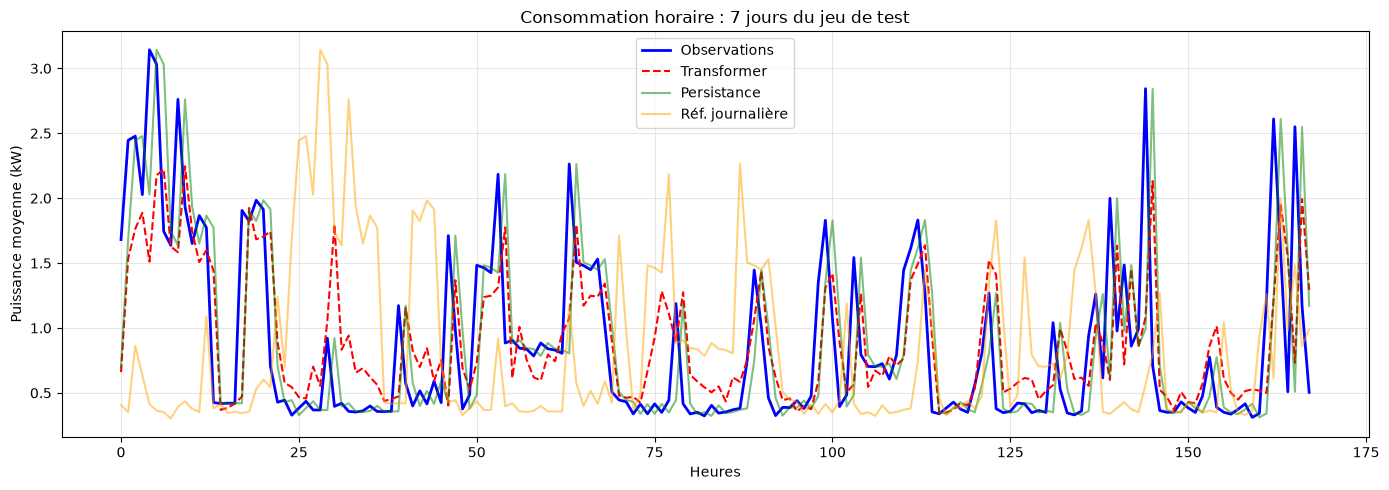

In [5]:
# 9
import matplotlib.pyplot as plt

idx_test = dates_cibles[test_mask]
# premier bloc de 168 heures réellement consécutives (sans trou de données)
debut = next(k for k in range(len(idx_test) - 167)
             if idx_test[k + 167] - idx_test[k] == 167)
s = slice(debut, debut + 168)

plt.figure(figsize=(14, 5))
plt.plot(reel[s], label="Observations", color="blue", linewidth=2)
plt.plot(pred[s], label="Transformer", color="red", linestyle="--")
plt.plot(persistance[s], label="Persistance", color="green", alpha=0.5)
plt.plot(journaliere[s], label="Réf. journalière", color="orange", alpha=0.5)
plt.title("Consommation horaire : 7 jours du jeu de test")
plt.xlabel("Heures"); plt.ylabel("Puissance moyenne (kW)")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

**10.1 – Le Transformer améliore-t-il les deux références ?**
Oui, d'après le tableau de la question 3.5 : MAE 0,341 kW contre 0,389 (persistance) et 0,513 (référence journalière), RMSE 0,490 kW contre 0,588 et 0,764. Le gain sur la persistance est d'environ 12 % en MAE et 17 % en RMSE. La référence journalière est ici la plus faible : à l'échelle d'un seul foyer, la consommation d'une même heure varie beaucoup d'un jour à l'autre, alors que l'heure précédente reste très informative. Sur le graphique, le Transformer suit la persistance en lissant les pics : il réagit avec un temps de retard et ne prévoit pas les pics soudains.

**10.2 – Une fenêtre de 168 heures permet-elle de mieux capturer les habitudes hebdomadaires ?**
Probablement : elle donne accès au même jour de la semaine précédente, donc aux habitudes hebdomadaires (week-end, jours de travail). Ce n'est pas testé ici : il faudrait relancer avec `fenetre = 168` et `EnergyTransformer(longueur=168)`. Elle coûte plus de calcul (l'attention est quadratique en la longueur) et demande plus de données.

**10.3 – Intérêt d'ajouter l'heure de la journée et le jour de la semaine ?**
Le modèle reçoit explicitement les cycles journalier et hebdomadaire au lieu de les deviner, ce qui aide surtout à prédire les pics de consommation.

**10.4 – Pourquoi normaliser uniquement à partir de l'entraînement ?**
Utiliser la moyenne et l'écart-type de toutes les données ferait fuiter de l'information du futur (validation/test) dans l'entraînement, et rendrait l'évaluation trop optimiste.

**10.5 – Adapter la préparation pour prédire une énergie en kWh ?**
L'énergie sur une heure vaut puissance moyenne (kW) × 1 h, donc la valeur reste la même sur un pas horaire. Pour un autre pas, on multiplierait par la durée en heures (ex. 0.25 pour 15 min), ou on sommerait les mesures en kW/60 au lieu de faire la moyenne.

## Exercice 2

Implémenter un mini-GPT pour générer du texte

Objectif : construire un Transformer autorégressif qui prédit le prochain caractère.

Il s’agit d’un petit modèle de type GPT entraîné depuis zéro. Une tokenisation par caractères simplifie l’exercice.

Données

Créer un fichier corpus.txt contenant quelques pages de texte, puis préparer le vocabulaire :

In [6]:
import torch

with open("corpus.txt", encoding="utf-8") as fichier:
    texte = fichier.read()

caracteres = sorted(set(texte))
stoi_car = {c: i for i, c in enumerate(caracteres)}
itos_car = {i: c for c, i in stoi_car.items()}

tokens = torch.tensor([stoi_car[c] for c in texte], dtype=torch.long)

# Découpage chronologique 90 % / 10 % : la validation sert à détecter la mémorisation
coupure = int(0.9 * len(tokens))
tokens_train, tokens_val = tokens[:coupure], tokens[coupure:]
print(f"{len(caracteres)} caractères distincts | train {len(tokens_train)} | val {len(tokens_val)}")

# Exemple d'une paire entrée/cible
longueur = 64
x = tokens[:longueur]
y = tokens[1:longueur + 1]

70 caractères distincts | train 6405 | val 712


Pour une entrée Bonjou, la cible est le texte décalé d’un caractère : chaque position apprend à prédire le caractère suivant.

Travail demandé
1. Implémenter un bloc GPT contenant :
   - une normalisation LayerNorm avant l’attention ;
   - une attention multi-têtes causale ;
   - une connexion résiduelle ;
   - une seconde normalisation ;
   - un MLP 64 → 256 → 64, avec activation GELU ;
   - une seconde connexion résiduelle.
2. Construire le modèle avec des embeddings de caractères et de positions, deux blocs, quatre têtes et une projection vers le vocabulaire.
3. Entraîner avec la perte d’entropie croisée sur toutes les positions.
4. Générer 200 caractères à partir d’une amorce en échantillonnant le caractère suivant.
5. Comparer les générations avec des températures de 0.5, 1.0 et 1.5.


In [7]:
# Bloc GPT
import torch.nn as nn
import torch.nn.functional as F

class BlocGPT(nn.Module):
    def __init__(self, dimension=64, tetes=4, dim_mlp=256, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dimension)
        self.attention = nn.MultiheadAttention(dimension, tetes, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(dimension)
        self.mlp = nn.Sequential(
            nn.Linear(dimension, dim_mlp),
            nn.GELU(),
            nn.Linear(dim_mlp, dimension),
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, masque):
        h = self.norm1(x)                                    # norm avant l'attention
        h, _ = self.attention(h, h, h, attn_mask=masque, need_weights=False)
        x = x + self.dropout(h)                              # résiduelle 1
        x = x + self.dropout(self.mlp(self.norm2(x)))        # norm 2 + MLP + résiduelle 2
        return x

In [8]:
# 2
class MiniGPT(nn.Module):
    def __init__(self, taille_vocabulaire, longueur_max=64, dimension=64,
                 nb_blocs=2, tetes=4, dropout=0.1):
        super().__init__()
        self.longueur_max = longueur_max
        self.emb_car = nn.Embedding(taille_vocabulaire, dimension)
        self.emb_pos = nn.Embedding(longueur_max, dimension)
        self.blocs = nn.ModuleList(
            [BlocGPT(dimension, tetes, 4 * dimension, dropout) for _ in range(nb_blocs)]
        )
        self.norm_finale = nn.LayerNorm(dimension)
        self.sortie = nn.Linear(dimension, taille_vocabulaire)

    def forward(self, ids):                                  # (B, T)
        T = ids.size(1)
        masque = torch.triu(
            torch.ones(T, T, dtype=torch.bool, device=ids.device), diagonal=1
        )
        pos = torch.arange(T, device=ids.device)
        x = self.emb_car(ids) + self.emb_pos(pos)            # (B, T, 64)
        for bloc in self.blocs:
            x = bloc(x, masque)                              # (B, T, 64)
        return self.sortie(self.norm_finale(x))              # (B, T, vocab)

In [9]:
# 3
import copy
torch.manual_seed(42)
appareil = "cuda" if torch.cuda.is_available() else "cpu"
taille_vocab_car = len(caracteres)
modele_gpt = MiniGPT(taille_vocab_car).to(appareil)
optimiseur_gpt = torch.optim.AdamW(modele_gpt.parameters(), lr=3e-3)
tokens_train, tokens_val = tokens_train.to(appareil), tokens_val.to(appareil)

def lot_aleatoire(source, taille_lot=32, longueur=64):
    debuts = torch.randint(0, len(source) - longueur - 1, (taille_lot,))
    x = torch.stack([source[d:d + longueur] for d in debuts])
    y = torch.stack([source[d + 1:d + longueur + 1] for d in debuts])  # décalé d'un cran
    return x, y

@torch.no_grad()
def perte_validation():
    modele_gpt.eval()
    debuts = range(0, len(tokens_val) - 65, 64)             # fenêtres sans recouvrement
    x = torch.stack([tokens_val[d:d + 64] for d in debuts])
    y = torch.stack([tokens_val[d + 1:d + 65] for d in debuts])
    logits = modele_gpt(x)
    return F.cross_entropy(logits.reshape(-1, taille_vocab_car), y.reshape(-1)).item()

meilleure_val, meilleur_etat, etape_max = float("inf"), None, 0
somme_train = 0.0
for etape in range(3000):
    modele_gpt.train()
    x, y = lot_aleatoire(tokens_train)
    logits = modele_gpt(x)                                   # (B, 64, vocab)
    perte = F.cross_entropy(logits.reshape(-1, taille_vocab_car), y.reshape(-1))
    optimiseur_gpt.zero_grad()
    perte.backward()
    optimiseur_gpt.step()
    somme_train += perte.item()

    if (etape + 1) % 100 == 0:
        pv = perte_validation()
        if pv < meilleure_val:                               # garder le meilleur modèle
            meilleure_val, meilleur_etat, etape_max = pv, copy.deepcopy(modele_gpt.state_dict()), etape + 1
        if (etape + 1) % 300 == 0:
            print(f"Étape {etape + 1:4d} | perte train {somme_train / 100:.4f} | perte val {pv:.4f}")
        somme_train = 0.0

modele_gpt.load_state_dict(meilleur_etat)
print(f"Meilleur modèle : étape {etape_max}, perte val {meilleure_val:.4f}")

Étape  300 | perte train 1.9143 | perte val 1.9035
Étape  600 | perte train 1.2096 | perte val 1.9437
Étape  900 | perte train 0.8178 | perte val 2.2219
Étape 1200 | perte train 0.6256 | perte val 2.5080
Étape 1500 | perte train 0.5201 | perte val 2.7325
Étape 1800 | perte train 0.4550 | perte val 2.8759
Étape 2100 | perte train 0.4127 | perte val 2.9432
Étape 2400 | perte train 0.3812 | perte val 3.1499
Étape 2700 | perte train 0.3585 | perte val 3.2309
Étape 3000 | perte train 0.3398 | perte val 3.3146
Meilleur modèle : étape 400, perte val 1.8282


**Lecture des pertes.** La perte d'entraînement continue de baisser (environ 0,34 à l'étape 3000), mais la perte de validation est minimale vers l'étape 400 (environ 1,83) puis remonte au-delà de 3,3 : le modèle finit par mémoriser le corpus (environ 7 000 caractères, très petit) au lieu de généraliser. Une perte d'entraînement très basse n'est donc pas un signe de qualité ici. Le notebook conserve le meilleur modèle selon la validation. Pour comparaison, deviner au hasard parmi 70 caractères donnerait une perte de ln 70 ≈ 4,25 : le modèle retenu apprend des régularités (syllabes, ponctuation, mots courts) mais pas encore de phrases cohérentes. Pour des textes plus lisibles, il faut un corpus beaucoup plus grand.

In [10]:
# 4
@torch.no_grad()
def generer(amorce, nb_caracteres=200, temperature=1.0):
    modele_gpt.eval()

    # Gestion des caractères absents du vocabulaire
    inconnus = sorted({c for c in amorce if c not in stoi_car})
    if inconnus:
        print(f"Attention : caractères ignorés (absents du corpus) : {inconnus}")
    amorce = "".join(c for c in amorce if c in stoi_car)

    # Si l'amorce est vide après filtrage, on prend un caractère par défaut
    if not amorce:
        amorce = itos_car[0]
        print(f"Amorce vide, utilisation de : {amorce!r}")

    ids = torch.tensor([[stoi_car[c] for c in amorce]], device=appareil)

    for _ in range(nb_caracteres):
        contexte = ids[:, -modele_gpt.longueur_max:]
        logits = modele_gpt(contexte)[:, -1, :] / max(temperature, 1e-5)
        probas = torch.softmax(logits, dim=-1)
        suivant = torch.multinomial(probas, num_samples=1)
        ids = torch.cat([ids, suivant], dim=1)

    return "".join(itos_car[i] for i in ids[0].tolist())


# Amorces utilisant uniquement des caractères présents dans le corpus
print(generer("Le ", 200, 0.8))
print(generer("L'intelligence", 200, 0.8))

Le jour les ses au courmains ettent des d'instrogréportisennenttermanter. peurtatit de es des plustrécu de et uneettronne à une mon anipeustreur de des pas peurtion icirogle ouvers une ou un mot con con 
L'intelligence entent des comprogreme et à autendrent les ous conettresinisées sients et :

« Pant-cest et présidituressionstrucires prestrussion ouvent des une le don sivelle de d'exécustercustes ces à distomatiti


In [11]:
# 5
amorce = "Le "   # uniquement des caractères présents dans le corpus

for T_ in [0.5, 1.0, 1.5]:
    print(f"\n===== Température {T_} =====")
    print(generer(amorce, 200, T_))


===== Température 0.5 =====
Le estionstitue un de comprendre l'ectes nouvent partisent une con oustrogrant un peur le des comancertainations iliste de ces peures dectections imans des ettellister des. Les pes peuventruistionstes de

===== Température 1.0 =====
Le capparaitéice comprendres pondres appreu à cendre une humachagenière une, rent h, samant « phumére séqueadoir cont cesfonstion est déces pré à peuves.

L'anthnoutrhilesesse apapprésistiqueus imantente

===== Température 1.5 =====
Le One rest cessosanalti, més, umon dest.

« 2qu'l'oulif pil e0s, à esvapprendathéculfhaitude, à ine, estaistion, et les de quisrechres syquavéettencagindion àr s'un exeautitelyt der, généemattrer »

Aux


Masque causal à utiliser avec torch.nn.MultiheadAttention

Formes attendues:

- Identifiants en entrée : (batch, 64)
- Représentations        : (batch, 64, 64)
- Logits                 : (batch, 64, taille_vocabulaire)
- Cibles                 : (batch, 64)

Vérification essentielle : en mode eval(), modifier un caractère futur ne doit pas modifier les logits des positions précédentes.

In [12]:
modele_gpt.eval()
with torch.no_grad():
    x, _ = lot_aleatoire(tokens_train, 1)
    x2 = x.clone()
    x2[0, 40] = (x2[0, 40] + 1) % taille_vocab_car           # changer un caractère futur
    l1, l2 = modele_gpt(x), modele_gpt(x2)

print("Positions < 40 identiques :", torch.allclose(l1[:, :40], l2[:, :40], atol=1e-6))
print("Positions >= 40 modifiées :", not torch.allclose(l1[:, 40:], l2[:, 40:]))

Positions < 40 identiques : True
Positions >= 40 modifiées : True


Questions
- Que se passe-t-il pendant l’entraînement si le masque causal est supprimé ?
- Quel effet la température a-t-elle sur la génération ?
- Pourquoi faut-il décaler les cibles d’une position ?

**Q1 – Que se passe-t-il à l'entraînement sans masque causal ?**
Chaque position voit le caractère qu'elle doit prédire (le suivant) et peut le copier. La perte tombe presque à 0, mais le modèle n'apprend rien d'utile : à la génération, il n'a pas le futur et produit du bruit.

**Q2 – Effet de la température ?**
Les logits sont divisés par T avant le softmax. T faible (0.5) : distribution piquée, le modèle choisit presque toujours le caractère le plus probable ; on obtient des suites de syllabes fréquentes qui ressemblent à du français (« comprendre », « une », « des ») mais qui se répètent. T élevée (1.5) : distribution aplatie, texte plus varié mais avec beaucoup plus de fautes, de caractères rares et de mots inventés (« 2qu'l'oulif », « e0s »). T = 1.0 est un compromis. Ici, même à T = 0.5 le texte n'est pas cohérent : le modèle est petit et son corpus minuscule, donc la température change le style du bruit plus qu'elle ne le corrige.

**Q3 – Pourquoi décaler les cibles d'une position ?**
À la position t, le modèle ne connaît que les caractères jusqu'à t et doit prédire celui de t+1. Sans décalage, la cible serait l'entrée elle-même et la tâche triviale.

## Exercice 3

Implémenter un mini-BERT pour retrouver des mots masqués

Objectif : entraîner un Transformer bidirectionnel à reconstruire des mots masqués grâce au contexte situé à gauche et à droite.

L’exercice reprend l’objectif de modélisation du langage masqué de BERT, sans reproduire l’ensemble de son préentraînement.

Données

Utiliser un petit corpus de phrases et une tokenisation par mots. Réserver les identifiants suivants :

In [13]:
PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4

Chaque phrase doit prendre la forme :

[CLS] le chat dort sur le canapé [SEP] [PAD] ...

Travail demandé

1. Construire le vocabulaire sur le corpus d’entraînement, puis encoder et compléter les phrases jusqu’à 32 tokens.
2. Sélectionner aléatoirement 15 % des tokens ordinaires, en excluant les tokens spéciaux. Pour les positions sélectionnées :
   - remplacer 80 % des tokens par [MASK] ;
   - remplacer 10 % par un token ordinaire aléatoire ;
   - conserver 10 % inchangés.
3. Construire un modèle avec :
   - embeddings de tokens et de positions de dimension 64 ;
   - deux couches Transformer Encoder à quatre têtes ;
   - attention bidirectionnelle, sans masque causal ;
   - masque de padding ;
   - projection finale vers le vocabulaire.
4. Calculer la perte uniquement sur les positions sélectionnées, y compris celles conservées inchangées.
5. Mesurer l’exactitude sur les tokens sélectionnés d’un jeu de validation et afficher les trois propositions les plus probables pour quelques mots masqués.
Préparation des cibles

In [14]:
# 1
import random, itertools
import torch, torch.nn as nn
from collections import Counter

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4
LONGUEUR = 32

# Corpus généré par gabarits (tu peux le remplacer par tes propres phrases)
sujets = ["le chat", "le chien", "l'enfant", "la fille", "le garçon", "l'oiseau"]
verbes = ["dort", "mange", "joue", "court", "regarde", "attend"]
lieux  = ["sur le canapé", "dans le jardin", "devant la maison", "sous la table",
          "près de la porte", "dans la cuisine"]
phrases = [f"{s} {v} {l}" for s, v, l in itertools.product(sujets, verbes, lieux)]

random.seed(42); torch.manual_seed(42)
random.shuffle(phrases)
coupure = int(0.85 * len(phrases))
train_phrases, val_phrases = phrases[:coupure], phrases[coupure:]

# Vocabulaire construit uniquement sur l'entraînement
compteur = Counter(m for p in train_phrases for m in p.split())
itos_mot = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"] + sorted(compteur)
stoi_mot = {m: i for i, m in enumerate(itos_mot)}
taille_vocab_mot = len(itos_mot)

def encoder(phrase):
    ids = [CLS] + [stoi_mot.get(m, UNK) for m in phrase.split()] + [SEP]
    ids = ids[:LONGUEUR]
    return ids + [PAD] * (LONGUEUR - len(ids))

train_ids = torch.tensor([encoder(p) for p in train_phrases])
val_ids   = torch.tensor([encoder(p) for p in val_phrases])
print(train_ids.shape, val_ids.shape, "| vocabulaire :", taille_vocab_mot)

torch.Size([183, 32]) torch.Size([33, 32]) | vocabulaire : 31


In [15]:
# 2
def masquer(input_ids, proba=0.15):
    entrees = input_ids.clone()
    ordinaires = input_ids > MASK                          # exclut les tokens spéciaux
    selection = (torch.rand(input_ids.shape) < proba) & ordinaires

    # Au moins une position sélectionnée par phrase
    for i in range(len(input_ids)):
        if not selection[i].any():
            candidats = ordinaires[i].nonzero(as_tuple=True)[0]
            if len(candidats) > 0:
                selection[i, candidats[torch.randint(len(candidats), (1,))]] = True

    tirage = torch.rand(input_ids.shape)
    vers_mask      = selection & (tirage < 0.8)                         # 80 % -> [MASK]
    vers_aleatoire = selection & (tirage >= 0.8) & (tirage < 0.9)       # 10 % -> mot aléatoire
    # les 10 % restants sont inchangés mais restent sélectionnés

    entrees[vers_mask] = MASK
    aleatoires = torch.randint(MASK + 1, taille_vocab_mot, input_ids.shape)
    entrees[vers_aleatoire] = aleatoires[vers_aleatoire]
    return entrees, selection

In [16]:
# 3
class MiniBERT(nn.Module):
    def __init__(self, taille_vocab_mot, longueur_max=LONGUEUR, dimension=64):
        super().__init__()
        self.emb_tok = nn.Embedding(taille_vocab_mot, dimension, padding_idx=PAD)
        self.emb_pos = nn.Embedding(longueur_max, dimension)
        couche = nn.TransformerEncoderLayer(
            d_model=dimension, nhead=4, dim_feedforward=4 * dimension,
            dropout=0.1, activation="gelu", batch_first=True, norm_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2,
                                              enable_nested_tensor=False)
        self.sortie = nn.Linear(dimension, taille_vocab_mot)

    def forward(self, ids):                                # (B, 32)
        masque_padding = (ids == PAD)                      # True = position ignorée
        pos = torch.arange(ids.size(1), device=ids.device)
        x = self.emb_tok(ids) + self.emb_pos(pos)          # (B, 32, 64)
        x = self.encodeur(x, src_key_padding_mask=masque_padding)  # pas de masque causal
        return self.sortie(x)                              # (B, 32, vocab)

modele_bert = MiniBERT(taille_vocab_mot)
optimiseur_bert = torch.optim.AdamW(modele_bert.parameters(), lr=1e-3)
critere_bert = nn.CrossEntropyLoss(ignore_index=-100)

In [17]:
# 4
def calculer_loss(input_ids, entrees, positions_selectionnees):
    labels = input_ids.clone()
    labels[~positions_selectionnees] = -100                # ignoré par la perte
    logits = modele_bert(entrees)
    return critere_bert(logits.reshape(-1, taille_vocab_mot), labels.reshape(-1)), logits

for epoch in range(200):
    modele_bert.train()
    perm = torch.randperm(len(train_ids))
    total, n = 0.0, 0
    for debut in range(0, len(perm), 32):
        batch = train_ids[perm[debut:debut + 32]]
        entrees, sel = masquer(batch)                        # nouveau masquage à chaque fois
        loss, _ = calculer_loss(batch, entrees, sel)
        optimiseur_bert.zero_grad(); loss.backward(); optimiseur_bert.step()
        total += loss.item() * len(batch); n += len(batch)
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1:3d} | perte {total / n:.4f}")

Epoch  20 | perte 0.8015
Epoch  40 | perte 0.5950
Epoch  60 | perte 0.5701
Epoch  80 | perte 0.5721
Epoch 100 | perte 0.6422
Epoch 120 | perte 0.5240
Epoch 140 | perte 0.4463
Epoch 160 | perte 0.4629
Epoch 180 | perte 0.5606
Epoch 200 | perte 0.4904


In [18]:
# 5
# Masquage de validation fixé une fois pour toutes
torch.manual_seed(0)
val_entrees, val_sel = masquer(val_ids)

modele_bert.eval()
with torch.no_grad():
    logits = modele_bert(val_entrees)
    pred = logits.argmax(-1)
    exactitude = (pred[val_sel] == val_ids[val_sel]).float().mean().item()
    probas = torch.softmax(logits, dim=-1)
print(f"Exactitude sur les tokens sélectionnés (validation) : {exactitude:.2%}")

# Trois propositions les plus probables pour quelques mots masqués
for i in range(5):
    for j in val_sel[i].nonzero(as_tuple=True)[0].tolist():
        top_p, top_i = probas[i, j].topk(3)
        vu = " ".join(itos_mot[t] for t in val_entrees[i] if t != PAD)
        print(f"\nEntrée : {vu}")
        print(f"Mot attendu : {itos_mot[val_ids[i, j]]}")
        for p, t in zip(top_p, top_i):
            print(f"   {p.item():6.2%}  {itos_mot[t]}")

Exactitude sur les tokens sélectionnés (validation) : 56.10%

Entrée : [CLS] la [MASK] [MASK] sur le canapé [SEP]
Mot attendu : fille
   99.66%  fille
    0.10%  chat
    0.08%  chien

Entrée : [CLS] la [MASK] [MASK] sur le canapé [SEP]
Mot attendu : mange
   20.86%  regarde
   18.39%  joue
   18.23%  dort

Entrée : [CLS] le chien [MASK] devant la maison [SEP]
Mot attendu : court
   26.82%  dort
   23.64%  mange
   16.48%  joue

Entrée : [CLS] [MASK] attend dans la cuisine [SEP]
Mot attendu : l'enfant
   52.23%  l'oiseau
   47.33%  l'enfant
    0.11%  garçon

Entrée : [CLS] l'oiseau [MASK] dans la cuisine [SEP]
Mot attendu : court
   20.35%  mange
   19.52%  joue
   19.00%  regarde

Entrée : [CLS] [MASK] garçon attend dans la cuisine [SEP]
Mot attendu : le
   99.93%  le
    0.07%  la
    0.00%  de


**Lecture des résultats.** L'exactitude de 56 % est mesurée sur seulement 41 tokens (33 phrases de validation) : c'est une estimation très bruitée. Sur 200 masquages différents de la même validation, le modèle atteint environ 71,5 %, pour un plafond théorique d'environ 76,6 % (meilleure réponse possible connaissant la façon dont le corpus est généré). Par type de mot : lieux 95 % (plafond atteint), sujets 76 % (plafond 81 %), verbes 10 % (plafond 25 %, dont 10 % de tokens conservés visibles). Le verbe est indépendant du reste de la phrase (six choix équiprobables), donc imprévisible ; « l'enfant » et « l'oiseau » sont indiscernables quand le mot est masqué (environ 50 % chacun). Le verbe tombe même un peu sous le hasard (environ 17 %), probablement parce que les combinaisons de validation n'apparaissent jamais à l'entraînement : le modèle a mémorisé les verbes des phrases voisines.

Prévoir au moins une position sélectionnée par phrase contenant des tokens ordinaires.

Vérification essentielle : changer les valeurs aux positions de padding, tout en conservant le même masque de padding, ne doit pas affecter les prédictions des tokens utiles en mode eval().


In [19]:
modele_bert.eval()
with torch.no_grad():
    ids = val_entrees[:4].clone()
    ids2 = ids.clone()
    padding = (ids == PAD)
    ids2[padding] = torch.randint(MASK + 1, taille_vocab_mot, (int(padding.sum()),))

    def logits_avec_masque(i, masque):          # même masque de padding pour les deux
        pos = torch.arange(i.size(1))
        x = modele_bert.emb_tok(i) + modele_bert.emb_pos(pos)
        return modele_bert.sortie(modele_bert.encodeur(x, src_key_padding_mask=masque))

    l1 = logits_avec_masque(ids, padding)
    l2 = logits_avec_masque(ids2, padding)

utiles = ~padding
print("Prédictions des tokens utiles inchangées :",
      torch.allclose(l1[utiles], l2[utiles], atol=1e-5))

Prédictions des tokens utiles inchangées : True


Questions
- Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?
- Pourquoi calculer la perte uniquement sur les positions sélectionnées ?
- Pourquoi ce modèle ne génère-t-il pas directement du texte de la même manière que GPT ?

**Q1 – Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?**
L'encodeur n'a pas de masque causal : chaque position attend à toutes les autres, à gauche comme à droite. La tâche n'est pas de prédire le futur mais de reconstruire un mot caché.

**Q2 – Pourquoi calculer la perte uniquement sur les positions sélectionnées ?**
Les autres tokens sont visibles en entrée : les « prédire » serait de la copie triviale, ce qui noierait le signal d'apprentissage. Le `-100` fait ignorer ces positions par la perte.

**Q3 – Pourquoi ce modèle ne génère-t-il pas du texte comme GPT ?**
BERT est entraîné à remplir des trous avec le contexte des deux côtés, pas à estimer P(mot suivant | mots précédents). Il n'a donc pas de procédé naturel pour produire un texte mot après mot.